# Digital Image Processing Lab — Lab Task # 04
**Name:** Feeza Kulsoom  
**Roll No:** 2024-SE-03  
**Course:** Digital Image Processing Lab (5th Semester)

Original Image Loaded Successfully!
Width: 678 px | Height: 452 px | Array Shape: (452, 678, 3)


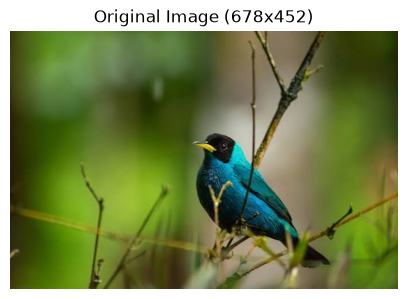

In [1]:
import os
import math
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

def load_and_validate_image(image_path):
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Error: Image file '{image_path}' does not exist.")

    bgr_image = cv.imread(image_path, cv.IMREAD_COLOR)
    if bgr_image is None:
        raise ValueError(f"Error: Failed to decode '{image_path}' as a valid image.")

    if bgr_image.ndim < 2 or bgr_image.shape[0] <= 0 or bgr_image.shape[1] <= 0:
        raise ValueError("Error: Decoded image has zero or invalid dimensions.")

    rgb_image = cv.cvtColor(bgr_image, cv.COLOR_BGR2RGB)
    return rgb_image

original_img = load_and_validate_image("image.jpg")
height, width = original_img.shape[:2]
print(f"Original Image Loaded Successfully!")
print(f"Width: {width} px | Height: {height} px | Array Shape: {original_img.shape}")

plt.figure(figsize=(5, 5))
plt.imshow(original_img)
plt.title(f"Original Image ({width}x{height})")
plt.axis("off")
plt.show()

In [2]:
MAX_OUTPUT_WIDTH = 5000
MAX_OUTPUT_HEIGHT = 5000

INTERPOLATION_MAP = {
    "nearest": cv.INTER_NEAREST,
    "bilinear": cv.INTER_LINEAR,
    "bicubic": cv.INTER_CUBIC,
    "lanczos": cv.INTER_LANCZOS4
}

def _validate_finite_number(val, name):
    if isinstance(val, bool) or not isinstance(val, (int, float, np.number)):
        raise TypeError(f"Parameter '{name}' must be a numeric value, got {type(val).__name__}.")
    if not math.isfinite(float(val)):
        raise ValueError(f"Parameter '{name}' must be finite (cannot be NaN or Inf).")
    return float(val)

def _validate_int_coordinate(val, name):
    if isinstance(val, bool) or not isinstance(val, (int, np.integer)):
        raise TypeError(f"Coordinate '{name}' must be an integer, got {type(val).__name__}.")
    return int(val)

def transform(image, operation, **params):
    # Validate input image
    if image is None or not isinstance(image, np.ndarray):
        raise TypeError("Input image must be a valid NumPy ndarray.")
    if image.ndim < 2 or image.shape[0] <= 0 or image.shape[1] <= 0:
        raise ValueError("Input image must have nonzero height and width.")
    
    if not isinstance(operation, str) or not operation.strip():
        raise ValueError("Operation name must be a non-empty string.")
    
    op = operation.strip().lower()
    src_h, src_w = image.shape[:2]
    img_copy = image.copy()  # Keep original image unchanged

    # 1. SCALING / RESIZING
    if op in ("scale", "scaling", "resize", "resizing"):
        if "fx" not in params or "fy" not in params:
            raise ValueError("Scaling requires 'fx' and 'fy' scale factors.")
        fx = _validate_finite_number(params["fx"], "fx")
        fy = _validate_finite_number(params["fy"], "fy")
        if fx <= 0 or fy <= 0:
            raise ValueError("Scale factors 'fx' and 'fy' must be strictly greater than zero.")
        
        interp_name = str(params.get("interpolation", "bilinear")).strip().lower()
        if interp_name not in INTERPOLATION_MAP:
            raise ValueError(f"Unsupported interpolation '{interp_name}'. Choose from {list(INTERPOLATION_MAP.keys())}.")
        
        out_w = int(round(src_w * fx))
        out_h = int(round(src_h * fy))
        if out_w < 1 or out_h < 1:
            raise ValueError(f"Resulting dimensions ({out_w}x{out_h}) would produce an empty image (< 1 px).")
        if out_w > MAX_OUTPUT_WIDTH or out_h > MAX_OUTPUT_HEIGHT:
            raise ValueError(f"Output size ({out_w}x{out_h}) exceeds maximum limit ({MAX_OUTPUT_WIDTH}x{MAX_OUTPUT_HEIGHT}).")
        
        return cv.resize(img_copy, (out_w, out_h), interpolation=INTERPOLATION_MAP[interp_name])

    # 2. CROPPING
    elif op in ("crop", "cropping"):
        required = ("left", "top", "right", "bottom")
        for key in required:
            if key not in params:
                raise ValueError(f"Cropping requires '{key}' coordinate.")
        left = _validate_int_coordinate(params["left"], "left")
        top = _validate_int_coordinate(params["top"], "top")
        right = _validate_int_coordinate(params["right"], "right")
        bottom = _validate_int_coordinate(params["bottom"], "bottom")
        
        if not (0 <= left < right <= src_w):
            raise ValueError(f"Invalid horizontal crop range: require 0 <= left ({left}) < right ({right}) <= {src_w}.")
        if not (0 <= top < bottom <= src_h):
            raise ValueError(f"Invalid vertical crop range: require 0 <= top ({top}) < bottom ({bottom}) <= {src_h}.")
        
        return img_copy[top:bottom, left:right].copy()

    # 3. FLIPPING
    elif op in ("flip", "flipping"):
        if "direction" not in params:
            raise ValueError("Flipping requires 'direction' ('horizontal', 'vertical', or 'both').")
        direction = str(params["direction"]).strip().lower()
        flip_codes = {"horizontal": 1, "vertical": 0, "both": -1}
        if direction not in flip_codes:
            raise ValueError(f"Unsupported flip direction '{direction}'. Must be 'horizontal', 'vertical', or 'both'.")
        
        return cv.flip(img_copy, flip_codes[direction])

    # 4. TRANSLATION
    elif op in ("translate", "translation"):
        if "tx" not in params or "ty" not in params:
            raise ValueError("Translation requires 'tx' and 'ty' offsets in pixels.")
        tx = _validate_finite_number(params["tx"], "tx")
        ty = _validate_finite_number(params["ty"], "ty")
        
        M = np.float32([[1, 0, tx], [0, 1, ty]])
        return cv.warpAffine(img_copy, M, (src_w, src_h), borderMode=cv.BORDER_CONSTANT, borderValue=(0, 0, 0))

    # 5. ROTATION
    elif op in ("rotate", "rotation"):
        if "angle" not in params:
            raise ValueError("Rotation requires 'angle' in degrees.")
        angle = _validate_finite_number(params["angle"], "angle")
        
        if "expand" not in params or not isinstance(params["expand"], bool):
            raise ValueError("Rotation requires boolean 'expand' parameter (True or False).")
        expand = params["expand"]
        
        # Note: OpenCV getRotationMatrix2D uses positive angles for counter-clockwise rotation
        center = (src_w / 2.0, src_h / 2.0)
        M = cv.getRotationMatrix2D(center, angle, 1.0)
        
        if not expand:
            return cv.warpAffine(img_copy, M, (src_w, src_h), borderMode=cv.BORDER_CONSTANT, borderValue=(0, 0, 0))
        else:
            cos_a = abs(M[0, 0])
            sin_a = abs(M[0, 1])
            new_w = int(round((src_h * sin_a) + (src_w * cos_a)))
            new_h = int(round((src_h * cos_a) + (src_w * sin_a)))
            if new_w > MAX_OUTPUT_WIDTH or new_h > MAX_OUTPUT_HEIGHT:
                raise ValueError(f"Expanded canvas ({new_w}x{new_h}) exceeds maximum limit ({MAX_OUTPUT_WIDTH}x{MAX_OUTPUT_HEIGHT}).")
            M[0, 2] += (new_w / 2.0) - center[0]
            M[1, 2] += (new_h / 2.0) - center[1]
            return cv.warpAffine(img_copy, M, (new_w, new_h), borderMode=cv.BORDER_CONSTANT, borderValue=(0, 0, 0))

    else:
        raise ValueError(f"Unknown operation '{operation}'. Supported: scaling, cropping, flipping, translation, rotation.")

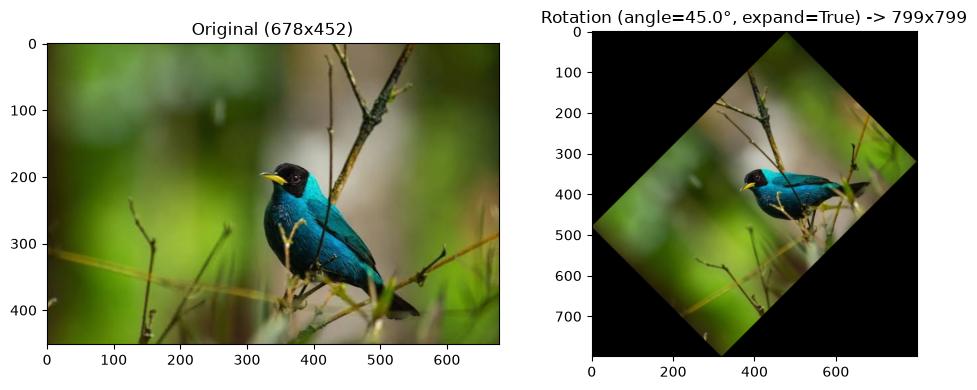

In [3]:
def prompt_float(prompt_msg):
    while True:
        raw = input(prompt_msg).strip()
        try:
            val = float(raw)
            if not math.isfinite(val):
                print("Invalid input: value must be finite (not NaN or Inf). Please try again.")
                continue
            return val
        except ValueError:
            print(f"Invalid input '{raw}': please enter a valid numeric value.")

def prompt_int(prompt_msg):
    while True:
        raw = input(prompt_msg).strip()
        try:
            return int(raw)
        except ValueError:
            print(f"Invalid input '{raw}': please enter a whole integer.")

def interactive_transform_ui(image):
    valid_ops = ["scaling", "cropping", "flipping", "translation", "rotation"]
    while True:
        op = input(f"Select operation {valid_ops}: ").strip().lower()
        if op not in valid_ops:
            print(f"Unsupported operation '{op}'. Please choose from {valid_ops}.")
            continue
        
        try:
            if op == "scaling":
                fx = prompt_float("Enter horizontal scale factor (fx > 0): ")
                fy = prompt_float("Enter vertical scale factor (fy > 0): ")
                interp = input("Enter interpolation (nearest, bilinear, bicubic, lanczos): ").strip().lower()
                result = transform(image, op, fx=fx, fy=fy, interpolation=interp)
                label = f"Scaling (fx={fx}, fy={fy}, {interp})"
            elif op == "cropping":
                left = prompt_int("Enter left coordinate: ")
                top = prompt_int("Enter top coordinate: ")
                right = prompt_int("Enter right coordinate: ")
                bottom = prompt_int("Enter bottom coordinate: ")
                result = transform(image, op, left=left, top=top, right=right, bottom=bottom)
                label = f"Cropping ({left},{top},{right},{bottom})"
            elif op == "flipping":
                direction = input("Enter direction (horizontal, vertical, both): ").strip().lower()
                result = transform(image, op, direction=direction)
                label = f"Flipping ({direction})"
            elif op == "translation":
                tx = prompt_float("Enter horizontal offset tx (pixels): ")
                ty = prompt_float("Enter vertical offset ty (pixels): ")
                result = transform(image, op, tx=tx, ty=ty)
                label = f"Translation (tx={tx}, ty={ty})"
            elif op == "rotation":
                angle = prompt_float("Enter rotation angle in degrees (+ = CCW, - = CW): ")
                exp_raw = input("Expand canvas? (yes/no): ").strip().lower()
                if exp_raw not in ("yes", "no", "true", "false"):
                    print("Invalid choice: enter 'yes' or 'no'.")
                    continue
                expand = exp_raw in ("yes", "true")
                result = transform(image, op, angle=angle, expand=expand)
                label = f"Rotation (angle={angle}°, expand={expand})"
            
            out_h, out_w = result.shape[:2]
            fig, axes = plt.subplots(1, 2, figsize=(10, 4))
            axes[0].imshow(image)
            axes[0].set_title(f"Original ({image.shape[1]}x{image.shape[0]})")
            axes[1].imshow(result)
            axes[1].set_title(f"{label} -> {out_w}x{out_h}")
            plt.tight_layout()
            plt.show()
            return result
        except Exception as e:
            print(f"Validation Error: {e}\nPlease re-enter valid parameters.\n")

# Run interactive prompt example
user_output = interactive_transform_ui(original_img)

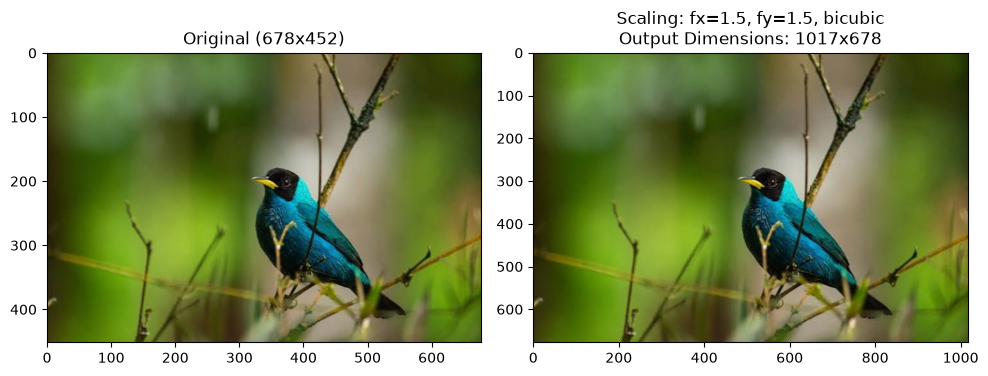

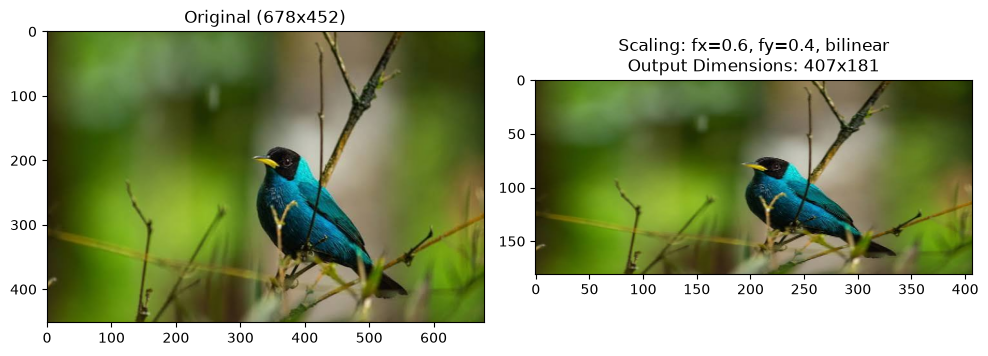

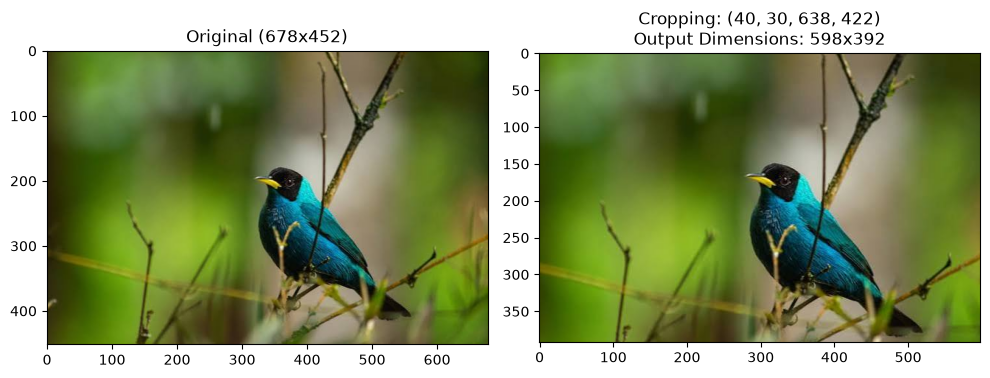

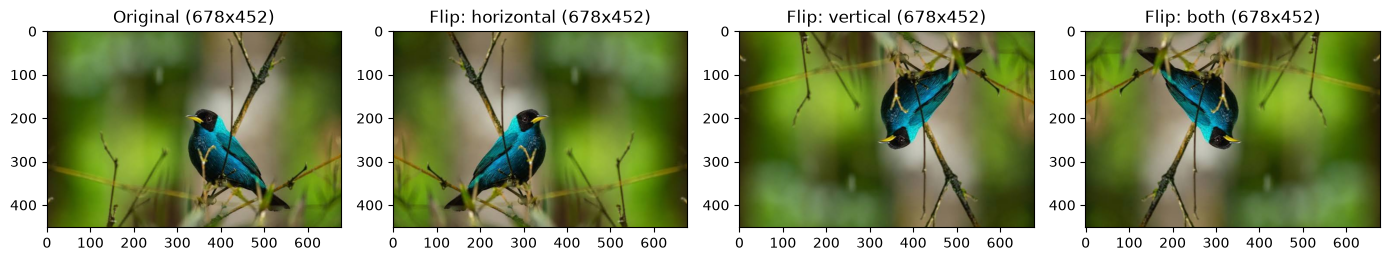

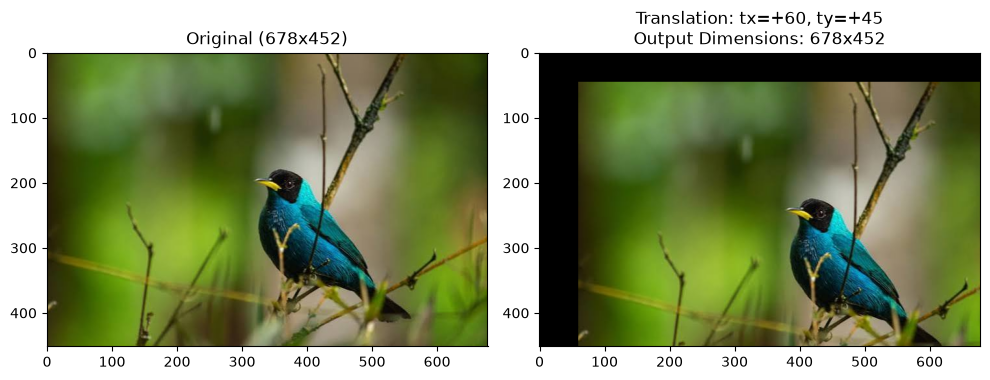

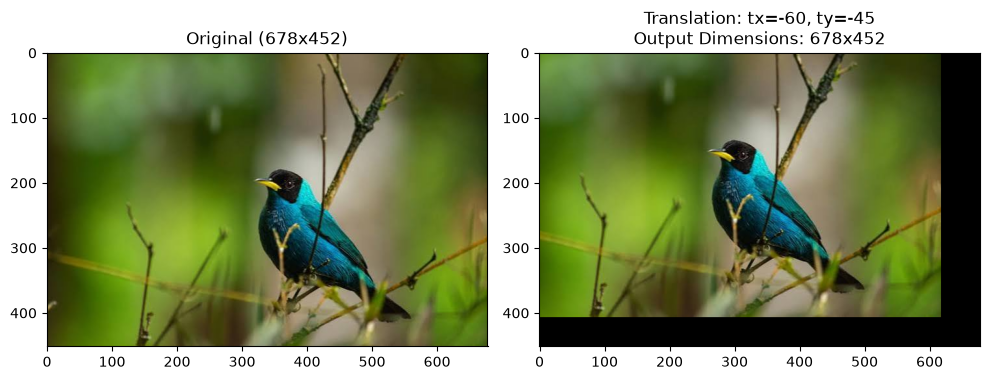

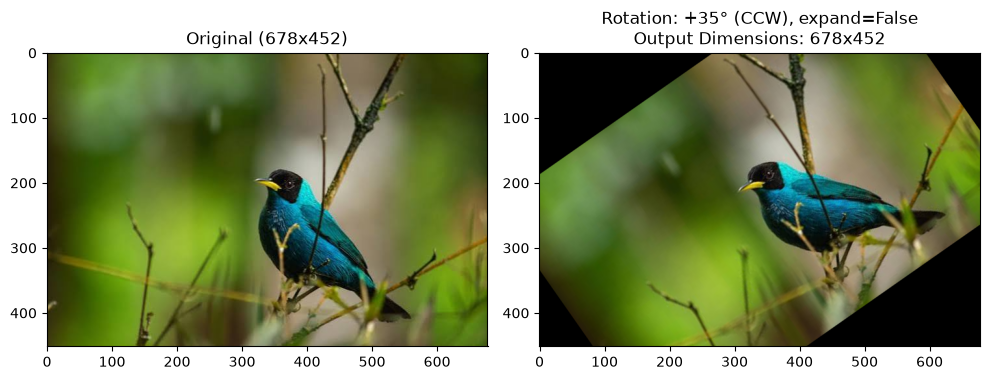

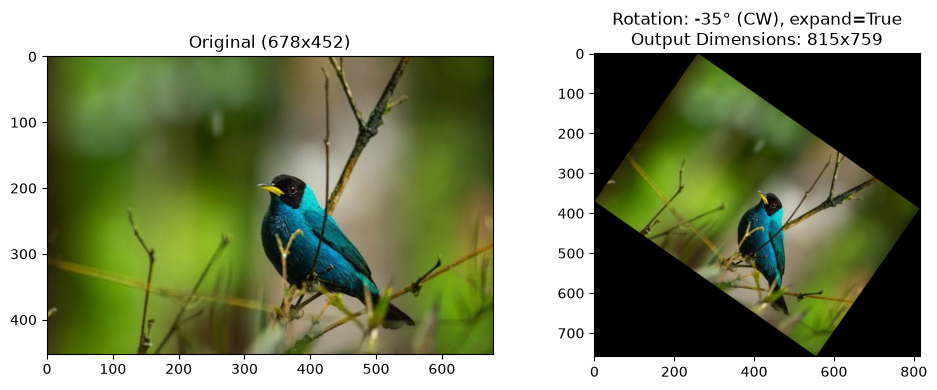

In [4]:
os.makedirs("transformed_outputs", exist_ok=True)

def show_and_save(orig, trans, label, filename):
    oh, ow = orig.shape[:2]
    th, tw = trans.shape[:2]
    cv.imwrite(os.path.join("transformed_outputs", filename), cv.cvtColor(trans, cv.COLOR_RGB2BGR))
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(orig)
    axes[0].set_title(f"Original ({ow}x{oh})")
    axes[1].imshow(trans)
    axes[1].set_title(f"{label}\nOutput Dimensions: {tw}x{th}")
    plt.tight_layout()
    plt.show()

# 1. Scaling: Proportional Enlargement & Non-Proportional Reduction
scale_up = transform(original_img, "scaling", fx=1.5, fy=1.5, interpolation="bicubic")
show_and_save(original_img, scale_up, "Scaling: fx=1.5, fy=1.5, bicubic", "01_scale_enlarge.png")

scale_down = transform(original_img, "scaling", fx=0.6, fy=0.4, interpolation="bilinear")
show_and_save(original_img, scale_down, "Scaling: fx=0.6, fy=0.4, bilinear", "02_scale_nonprop_reduce.png")

# 2. Cropping
crop_img = transform(original_img, "cropping", left=40, top=30, right=width-40, bottom=height-30)
show_and_save(original_img, crop_img, f"Cropping: (40, 30, {width-40}, {height-30})", "03_cropped.png")

# 3. Flipping (All Three Directions)
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(original_img)
axes[0].set_title(f"Original ({width}x{height})")
for idx, d in enumerate(["horizontal", "vertical", "both"], start=1):
    flipped = transform(original_img, "flipping", direction=d)
    cv.imwrite(f"transformed_outputs/04_flip_{d}.png", cv.cvtColor(flipped, cv.COLOR_RGB2BGR))
    axes[idx].imshow(flipped)
    axes[idx].set_title(f"Flip: {d} ({flipped.shape[1]}x{flipped.shape[0]})")
plt.tight_layout()
plt.show()

# 4. Translation (Opposite Directions)
trans_pos = transform(original_img, "translation", tx=60, ty=45)
show_and_save(original_img, trans_pos, "Translation: tx=+60, ty=+45", "05_translate_pos.png")

trans_neg = transform(original_img, "translation", tx=-60, ty=-45)
show_and_save(original_img, trans_neg, "Translation: tx=-60, ty=-45", "06_translate_neg.png")

# 5. Rotation (Positive = Counter-Clockwise, Negative = Clockwise, Expand True/False)
rot_pos_crop = transform(original_img, "rotation", angle=35, expand=False)
show_and_save(original_img, rot_pos_crop, "Rotation: +35° (CCW), expand=False", "07_rotate_pos_noexpand.png")

rot_neg_exp = transform(original_img, "rotation", angle=-35, expand=True)
show_and_save(original_img, rot_neg_exp, "Rotation: -35° (CW), expand=True", "08_rotate_neg_expand.png")

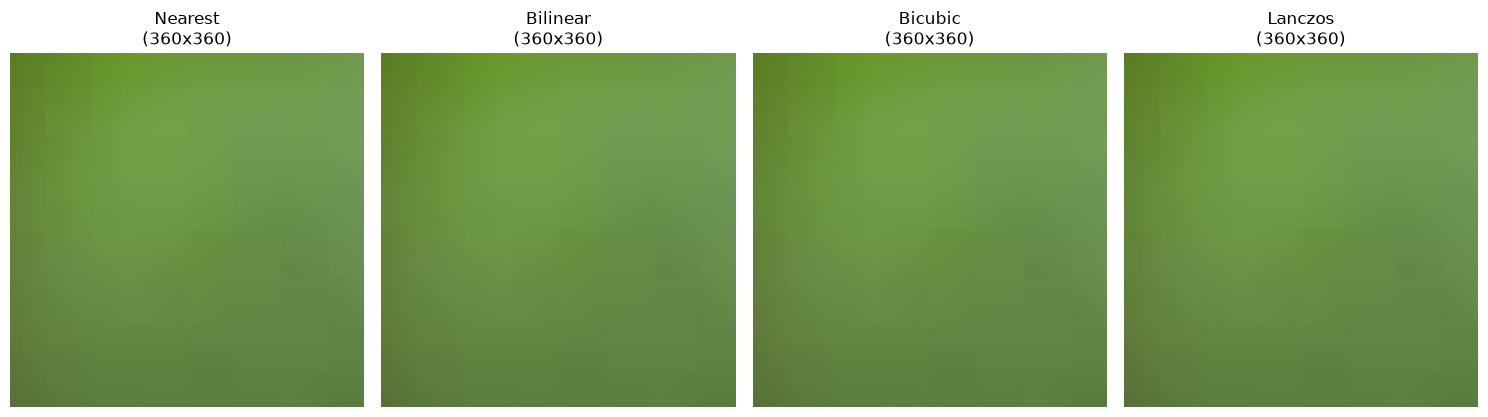

In [5]:
# Extract a small patch with sharp edges/details
patch = transform(original_img, "cropping", left=50, top=50, right=110, bottom=110)

methods = ["nearest", "bilinear", "bicubic", "lanczos"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, m in zip(axes, methods):
    enlarged_patch = transform(patch, "scaling", fx=6.0, fy=6.0, interpolation=m)
    cv.imwrite(f"transformed_outputs/09_interp_{m}.png", cv.cvtColor(enlarged_patch, cv.COLOR_RGB2BGR))
    ax.imshow(enlarged_patch)
    ax.set_title(f"{m.capitalize()}\n({enlarged_patch.shape[1]}x{enlarged_patch.shape[0]})")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
invalid_test_cases = [
    ("Scaling (Zero/Negative Factor)", lambda: transform(original_img, "scaling", fx=-1.5, fy=1.0, interpolation="bilinear")),
    ("Cropping (Inverted/Out-of-Bounds)", lambda: transform(original_img, "cropping", left=100, top=20, right=50, bottom=100)),
    ("Flipping (Unsupported Direction)", lambda: transform(original_img, "flipping", direction="diagonal")),
    ("Translation (NaN Offset)", lambda: transform(original_img, "translation", tx=float("nan"), ty=10)),
    ("Rotation (Nonnumeric Angle)", lambda: transform(original_img, "rotation", angle="forty-five", expand=True)),
    ("Unknown Operation", lambda: transform(original_img, "shear", shx=0.5))
]

for test_name, fn in invalid_test_cases:
    try:
        fn()
        print(f"[UNEXPECTED PASS] {test_name}")
    except Exception as err:
        print(f"[REJECTED AS EXPECTED] {test_name}\n   -> {type(err).__name__}: {err}")

[REJECTED AS EXPECTED] Scaling (Zero/Negative Factor)
   -> ValueError: Scale factors 'fx' and 'fy' must be strictly greater than zero.
[REJECTED AS EXPECTED] Cropping (Inverted/Out-of-Bounds)
   -> ValueError: Invalid horizontal crop range: require 0 <= left (100) < right (50) <= 678.
[REJECTED AS EXPECTED] Flipping (Unsupported Direction)
   -> ValueError: Unsupported flip direction 'diagonal'. Must be 'horizontal', 'vertical', or 'both'.
[REJECTED AS EXPECTED] Translation (NaN Offset)
   -> ValueError: Parameter 'tx' must be finite (cannot be NaN or Inf).
[REJECTED AS EXPECTED] Rotation (Nonnumeric Angle)
   -> TypeError: Parameter 'angle' must be a numeric value, got str.
[REJECTED AS EXPECTED] Unknown Operation
   -> ValueError: Unknown operation 'shear'. Supported: scaling, cropping, flipping, translation, rotation.


In [7]:
id_scale = transform(original_img, "scaling", fx=1.0, fy=1.0, interpolation="bilinear")
id_trans = transform(original_img, "translation", tx=0, ty=0)
id_rot = transform(original_img, "rotation", angle=0, expand=False)

print("Identity Scale Exact Match:", np.array_equal(original_img, id_scale))
print("Identity Translation Exact Match:", np.array_equal(original_img, id_trans))
print("Identity Rotation Exact Match:", np.array_equal(original_img, id_rot))

Identity Scale Exact Match: True
Identity Translation Exact Match: True
Identity Rotation Exact Match: True


## Observations & Conceptual Analysis

### 1. Interpolation Methods Comparison
* **Nearest-Neighbour:** Produces sharp, blocky, stair-stepped (aliased) pixel boundaries because each output pixel simply copies its closest source pixel without blending[cite: 5].
* **Bilinear:** Smooths out blocky pixelation by computing a weighted average of the 2x2 neighborhood, though diagonal edges appear noticeably softer and slightly blurred[cite: 5].
* **Bicubic:** Uses a 4x4 pixel neighborhood with cubic polynomials, yielding noticeably crisper edges and smoother tonal gradients than bilinear interpolation[cite: 5].
* **Lanczos:** Uses a windowed sinc kernel over an 8x8 neighborhood, preserving the finest edge sharpness and micro-contrast, with occasional faint ringing halos near high-contrast transitions[cite: 5].

### 2. Identity Transformation Checks
| Identity Case | Expected Behaviour | Actual Behaviour | Status |
| :--- | :--- | :--- | :--- |
| Scaling (`fx=1.0, fy=1.0`)[cite: 5] | Output dimensions and pixel values remain identical to original image[cite: 5]. | Output shape and all pixel values matched original (`np.array_equal = True`)[cite: 5]. | Pass[cite: 5] |
| Translation (`tx=0, ty=0`)[cite: 5] | Zero pixel shift; no clipping or exposed black border regions[cite: 5]. | Output shape and all pixel values matched original (`np.array_equal = True`)[cite: 5]. | Pass[cite: 5] |
| Rotation (`angle=0°`, `expand=False`)[cite: 5] | Zero angular displacement around center; exact original image returned[cite: 5]. | Output shape and all pixel values matched original (`np.array_equal = True`)[cite: 5]. | Pass[cite: 5] |

### 3. Conceptual Observations
* **Image Coordinates vs. Array Indexing:** In 2D image coordinates, positions are expressed as `(x, y)` where `x` represents the horizontal column index (`0` to `width - 1`, left to right) and `y` represents the vertical row index (`0` to `height - 1`, top to bottom)[cite: 5]. In NumPy array indexing, however, arrays are stored in row-major order as `image[row, col]`, which corresponds to `image[y, x]`, so `image.shape` returns `(height, width, channels)` rather than `(width, height)`[cite: 5].
* **Aspect-Ratio Distortion:** When horizontal scale factor `fx` and vertical scale factor `fy` are unequal (`fx != fy`), the ratio of width to height changes, stretching or compressing shapes along one axis relative to the other and causing geometric aspect-ratio distortion[cite: 5].
* **Rotation Canvas Expansion & Positive-Angle Direction:** Rotating a rectangular image by an angle that is not a multiple of `90°` causes its corners to extend beyond the original width and height boundaries[cite: 5]. Setting `expand=False` keeps the original canvas size and clips the protruding corners; setting `expand=True` computes a larger bounding box so the entire rotated image fits without corner loss[cite: 5]. In OpenCV's `getRotationMatrix2D`, positive angles rotate counter-clockwise[cite: 5].
* **Translation Clipping & Exposed Background:** Because translation preserves the original canvas dimensions (`width x height`), shifting pixels by `(tx, ty)` pushes pixels moving past the destination boundary outside the frame (clipping), while vacating pixels on the opposite side that have no source mapping, leaving exposed background regions filled with black (`(0, 0, 0)`)[cite: 5].